# 2025 operational priority analysis

A screening tool for further investigation, not a causal or official MTA allocation model. The scorecard is generated from `sql/analysis/07_priority_components.sql` by `src/build_priority_scorecard.py`. See `reports/PRIORITIZATION_METHOD.md`.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
data = pd.read_csv(ROOT / 'data/analysis/line_priority_2025.csv')
meta = json.loads((ROOT / 'data/analysis/priority_metadata.json').read_text())
focus = ['F', 'Q', 'B', 'D']
display(data[['line_id','cjt_percent','net_additional_passenger_minutes','service_delivered_percent','score_baseline','rank_baseline','priority_quadrant']].head(10).round(2))

,line_id,cjt_percent,net_additional_passenger_minutes,service_delivered_percent,score_baseline,rank_baseline,priority_quadrant
0,F,81.75,2.319834e+08,91.63,90.00,1,High burden / Poor reliability
1,B,78.74,1.735488e+08,91.11,84.55,2,High burden / Poor reliability
2,Q,79.84,2.036499e+08,94.48,81.82,3,High burden / Poor reliability
3,R,82.63,1.803432e+08,90.33,74.55,4,High burden / Poor reliability
4,D,79.63,1.480834e+08,93.39,69.09,5,Lower burden / Poor reliability
5,NW,84.70,1.979816e+08,93.18,68.18,6,High burden / Poor reliability
6,E,85.17,1.803696e+08,92.25,63.64,7,High burden / Better reliability
7,M,80.74,1.258079e+08,93.35,62.73,8,Lower burden / Poor reliability
8,2,84.95,1.613613e+08,93.22,54.55,9,Lower burden / Better reliability
9,A,84.19,1.685207e+08,96.10,54.55,9,High burden / Poor reliability


## Priority matrix

Vertical and horizontal dividers are the 2025 medians across 23 comparison groups. Bubble area represents estimated passenger trips. The dividers are descriptive, not targets.

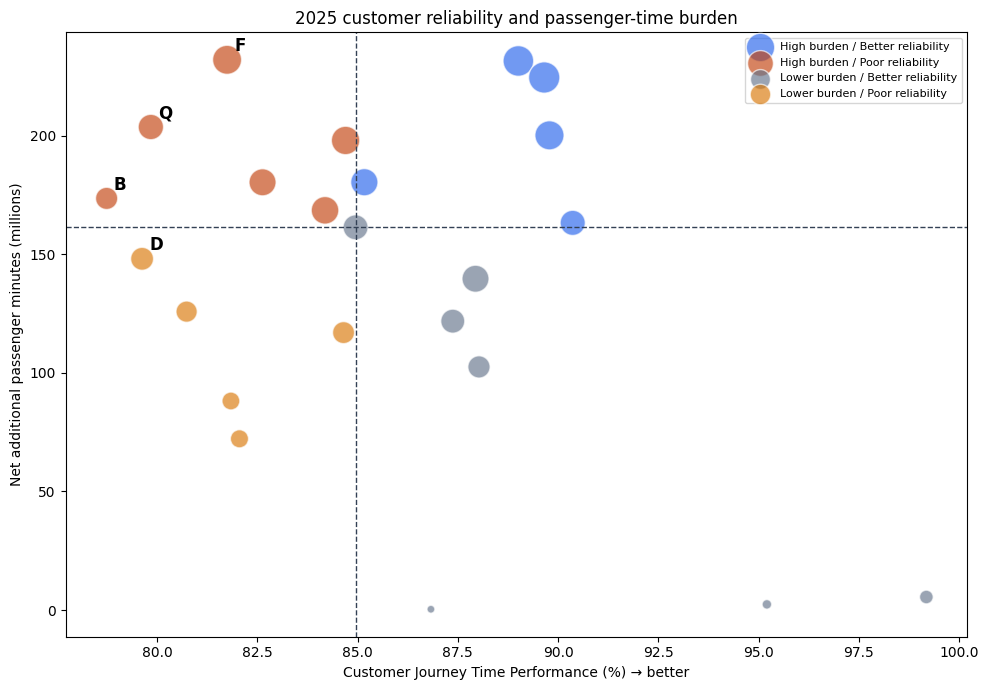

In [2]:
fig, ax = plt.subplots(figsize=(10, 7))
colors = {'High burden / Poor reliability':'#c2410c','High burden / Better reliability':'#2563eb','Lower burden / Poor reliability':'#d97706','Lower burden / Better reliability':'#64748b'}
for label, group in data.groupby('priority_quadrant'):
    ax.scatter(group.cjt_percent, group.net_additional_passenger_minutes / 1e6, s=group.passenger_trips / 3e5 + 30, alpha=.65, color=colors[label], label=label, edgecolors='white')
ax.axvline(meta['quadrant_cutoffs']['cjt_percent_median'], color='#334155', ls='--', lw=1)
ax.axhline(meta['quadrant_cutoffs']['net_additional_passenger_minutes_median']/1e6, color='#334155', ls='--', lw=1)
for row in data.itertuples():
    if row.line_id in focus:
        ax.annotate(row.line_id, (row.cjt_percent, row.net_additional_passenger_minutes/1e6), xytext=(5, 6), textcoords='offset points', fontsize=12, weight='bold')
ax.set(xlabel='Customer Journey Time Performance (%) → better', ylabel='Net additional passenger minutes (millions)', title='2025 customer reliability and passenger-time burden')
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()

## F, Q, B, D: underlying measures and history

CJTP is passenger weighted. AJT uses summed minutes divided by summed trips. Delay and major-incident sources are separate diagnostics and are not added.

,line_id,passenger_trips,cjt_2022_percent,cjt_2023_percent,cjt_2024_percent,cjt_percent,cjt_yoy_change_pp,ajt_minutes_per_trip,net_additional_passenger_minutes,weekday_delay_incidents,weekday_major_incidents,service_delivered_percent,priority_quadrant
0,F,1.216468e+08,81.64,82.15,81.37,81.75,0.38,1.91,2.319834e+08,4021,46.0,91.63,High burden / Poor reliability
1,Q,9.102347e+07,78.89,80.15,79.65,79.84,0.20,2.24,2.036499e+08,2823,27.0,94.48,High burden / Poor reliability
2,B,6.752358e+07,76.18,77.71,76.29,78.74,2.45,2.57,1.735488e+08,2087,30.0,91.11,High burden / Poor reliability
3,D,7.250363e+07,76.16,77.34,76.93,79.63,2.69,2.04,1.480834e+08,2774,29.0,93.39,Lower burden / Poor reliability


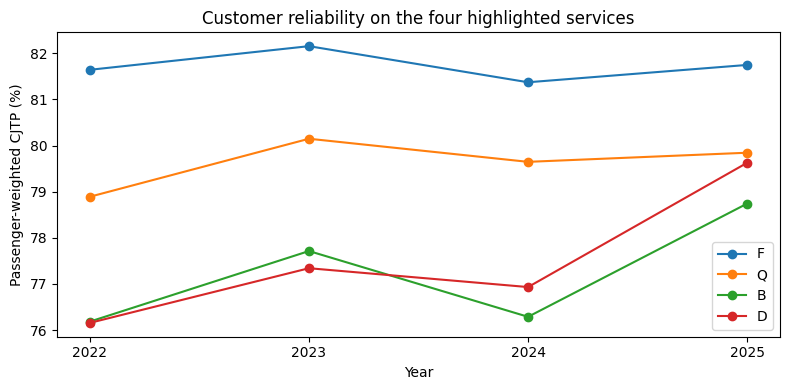

In [3]:
cols = ['line_id','passenger_trips','cjt_2022_percent','cjt_2023_percent','cjt_2024_percent','cjt_percent','cjt_yoy_change_pp','ajt_minutes_per_trip','net_additional_passenger_minutes','weekday_delay_incidents','weekday_major_incidents','service_delivered_percent','priority_quadrant']
display(data.set_index('line_id').loc[focus].reset_index()[cols].round(2))
fig, ax = plt.subplots(figsize=(8, 4))
for line in focus:
    row = data.set_index('line_id').loc[line]
    ax.plot([2022,2023,2024,2025], [row.cjt_2022_percent,row.cjt_2023_percent,row.cjt_2024_percent,row.cjt_percent], marker='o', label=line)
ax.set(xlabel='Year', ylabel='Passenger-weighted CJTP (%)', title='Customer reliability on the four highlighted services')
ax.set_xticks([2022,2023,2024,2025])
ax.legend()
fig.tight_layout()
plt.show()

## Weight sensitivity and unweighted Pareto frontier

The five scenarios change analytical weights only. Pareto status uses CJTP and net minutes without weights. A line is dominated when another line has at least as poor CJTP and at least as high burden, with one strict difference.

,line_id,rank_baseline,rank_equal,rank_reliability_focused,rank_burden_focused,rank_service_focused,rank_best_case,rank_worst_case,pareto_customer_frontier
0,F,1,1,2,1,1,1,2,True
1,B,2,2,1,3,1,1,3,True
2,Q,3,4,3,2,4,2,4,True
3,R,4,3,5,4,3,3,5,False
4,D,5,6,4,10,7,4,10,False
5,NW,6,5,7,5,4,4,7,False
6,E,7,7,8,6,6,6,8,False
7,M,8,8,6,12,8,6,12,False
8,2,9,9,11,13,10,9,13,False
9,A,9,12,9,11,14,9,14,False


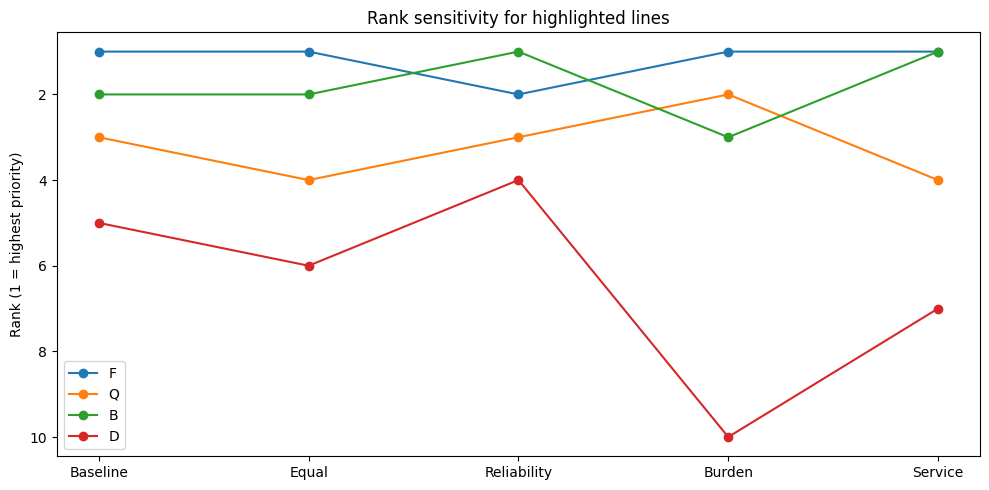

,line_id,cjt_percent,net_additional_passenger_minutes
0,F,81.75,2.319834e+08
1,B,78.74,1.735488e+08
2,Q,79.84,2.036499e+08


In [4]:
rank_cols = ['rank_baseline','rank_equal','rank_reliability_focused','rank_burden_focused','rank_service_focused']
display(data[['line_id',*rank_cols,'rank_best_case','rank_worst_case','pareto_customer_frontier']].head(12))
fig, ax = plt.subplots(figsize=(10, 5))
for line in focus:
    row = data.set_index('line_id').loc[line]
    ax.plot(range(len(rank_cols)), [row[c] for c in rank_cols], marker='o', label=line)
ax.set_xticks(range(len(rank_cols)), ['Baseline','Equal','Reliability','Burden','Service'])
ax.set(ylabel='Rank (1 = highest priority)', title='Rank sensitivity for highlighted lines')
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
plt.show()
display(data.loc[data.pareto_customer_frontier, ['line_id','cjt_percent','net_additional_passenger_minutes']].round(2))